# Task 1 — GPT-style character-level LLM from scratch (TinyStories)

**DATA 266 · Lab 1** · Every Transformer component (multi-head causal self-attention,
layer norm, feed-forward, residuals, embeddings, LM head) is written by hand below.
No `nn.MultiheadAttention`, `nn.Transformer*`, or `F.scaled_dot_product_attention` is used.

How this notebook is organised
1. Setup — member, config, seeds, raw log, hardware
2. Data preprocessing (1.1) — char tokenisation, `char_to_idx` / `idx_to_char`, 100K/10K split, fixed-length input→target windows
3. Model (1.2) — hand-written GPT + a unit test proving the causal mask works
4. Training (1.3) — cross-entropy, warm-up + LR schedule, ≥10 epochs, grad-norm / spike / NaN tracking
5. Evaluation — every Task 1 metric via the team's shared `eval_task1.py`
6. Generation — greedy + temperature sampling, generation speed and diversity
7. Failure analysis draft (1.4) + metrics_report.csv + results.md + manifest

Only the `MEMBER` line in the next cell differs between members' notebooks; everything
else (architecture, hyper-parameters) is read from `<task>/<member>/config.yaml`.

In [1]:
MEMBER = "ruchika_chaurasia"   # <-- the only line that differs between member notebooks
TASK = "task1_llm"

import importlib.util, os, subprocess, sys
from pathlib import Path

# install anything missing (Colab already has torch/numpy/matplotlib)
for pkg, mod in [("datasets", "datasets"), ("pyyaml", "yaml")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

def _find_root():
    if os.environ.get("REPO_ROOT"):
        return Path(os.environ["REPO_ROOT"]).resolve()
    here = Path.cwd().resolve()
    for q in [here, *here.parents]:
        if (q / "README.md").exists() and (q / "task1_llm").is_dir():
            return q
    raise FileNotFoundError("cd into the repo folder first (the one containing README.md)")

REPO_ROOT = _find_root()
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(REPO_ROOT / TASK / "common"))
print("repo root:", REPO_ROOT)

repo root: /app/data266-lab1


In [2]:
import json, math, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from common.runtime import (RawLogger, Timer, get_device, hardware_info, is_smoke, load_config,
                            peak_memory_mb, personal_params, reset_peak_memory, set_seed,
                            write_manifest, file_sha)
import eval_task1 as E

CFG = load_config(REPO_ROOT / TASK / MEMBER / "config.yaml")

# ---- personal parameters (course standing requirement 0.1) ----
if CFG.get("sid4") is not None:
    PP = personal_params(int(CFG["sid4"]))
    SID4, SEED, SLICE, HP_ID, CLS_A, CLS_B = (PP[k] for k in ["SID4", "SEED", "SLICE", "HP_ID", "CLS_A", "CLS_B"])
    print(f"SID4={SID4}  SEED={SEED}  SLICE={SLICE}  HP_ID={HP_ID}  CLS_A={CLS_A}  CLS_B={CLS_B}")
    print("(Lab 1 uses only SEED; the other parameters are listed per the standing requirement.)")
SEED = int(CFG["seed"])

# ---- smoke-test override: tiny run used by reproducibility/smoke_test.sh ----
if is_smoke():
    CFG["data"].update(n_train_stories=1500, n_val_stories=150, split_source="validation")
    CFG["model"].update(n_layer=2, n_head=2, d_model=64, block_size=64)
    CFG["train"].update(epochs=2, batch_size=16, warmup_steps=5, eval_max_seqs=64, resume=False)
    CFG["generation"].update(max_new_chars=80, samples_per_prompt=1)

OUT_ROOT = (REPO_ROOT / "_smoke" / TASK / MEMBER) if is_smoke() else (REPO_ROOT / TASK / MEMBER)
DIRS = {k: OUT_ROOT / k for k in ["data_processed", "checkpoints", "outputs"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
device = get_device()
log = RawLogger(REPO_ROOT, TASK, MEMBER)
HW = hardware_info()
log("member:", MEMBER, "| lineup:", CFG.get("lineup"), "| seed:", SEED, "| smoke:", is_smoke())
log("hardware:", json.dumps(HW))
log("config:", json.dumps(CFG))

SID4=8283  SEED=8283  SLICE=283  HP_ID=3  CLS_A=3  CLS_B=4
(Lab 1 uses only SEED; the other parameters are listed per the standing requirement.)
raw log started: reproducibility/raw_logs/task1_llm_ruchika_chaurasia_20261001_235055.log
member: ruchika_chaurasia | lineup: A | seed: 8283 | smoke: False
hardware: {"cpu": "Intel(R) Core(TM) Ultra 9 285K", "cpu_count": 24, "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.31", "python": "3.10.13", "torch": "2.11.0+cu128", "cuda_available": true, "gpu": "NVIDIA GeForce RTX 5090", "gpu_memory_gb": 31.84, "cuda": "12.8", "cudnn": 91900}
config: {"member": "ruchika_chaurasia", "lineup": "A", "sid4": 8283, "seed": 8283, "data": {"hf_name": "roneneldan/TinyStories", "split_source": "train", "local_text_file": null, "n_train_stories": 100000, "n_val_stories": 10000, "min_char_freq": 5}, "model": {"n_layer": 4, "n_head": 4, "d_model": 256, "block_size": 256, "dropout": 0.1, "ffn_mult": 4, "tie_weights": true}, "train": {"epochs"

## 1.1 Data preprocessing
* **Split** — sample 110,000 stories from the TinyStories *train* split with this member's own
  seed: 100,000 → train, 10,000 → validation. The indices are saved to `data_processed/` so the split is reproducible.
* **Cleaning** — Unicode NFKC normalisation and mapping of curly quotes/dashes to ASCII, so the
  vocabulary is not wasted on near-duplicate characters.
* **Character tokenisation** — every character is a token. Characters seen fewer than `min_char_freq`
  times in *train* become `<unk>`. Stories are joined with an end-of-story token so the model learns where stories stop.
* **Encodings** — our own `char_to_idx` / `idx_to_char` dictionaries.
* **Fixed-length sequences** — input = characters `[i, i+T)`, target = characters `[i+1, i+T+1)`.

In [3]:
UNK, EOS = "\x01", "\x03"          # special tokens (never appear in the cleaned text)
_TABLE = str.maketrans({"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-",
                        "\u2014": "-", "\u2026": "...", "\u00a0": " ", UNK: "", EOS: ""})

def clean(text: str) -> str:
    return unicodedata.normalize("NFKC", text).translate(_TABLE).strip()

def load_stories():
    dc = CFG["data"]
    n_total = dc["n_train_stories"] + dc["n_val_stories"]
    if dc.get("local_text_file"):   # fallback: TinyStories .txt file (stories separated by <|endoftext|>)
        raw = (REPO_ROOT / dc["local_text_file"]).read_text(encoding="utf-8")
        stories = [s for s in raw.split("<|endoftext|>") if s.strip()]
    else:
        from datasets import load_dataset
        ds = load_dataset(dc["hf_name"], split=dc.get("split_source", "train"))
        stories = ds
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(stories), size=n_total, replace=False)
    tr_idx, va_idx = idx[: dc["n_train_stories"]], idx[dc["n_train_stories"]:]
    get = (lambda ii: [stories[int(i)] for i in ii]) if isinstance(stories, list) \
        else (lambda ii: stories.select(ii.tolist())["text"])
    return get(tr_idx), get(va_idx), tr_idx, va_idx

with Timer() as t_load:
    train_raw, val_raw, tr_idx, va_idx = load_stories()
train_txt = [clean(s) for s in train_raw]
val_txt = [clean(s) for s in val_raw]
(DIRS["data_processed"] / "split_indices.json").write_text(
    json.dumps({"seed": SEED, "source": CFG["data"]["hf_name"], "train": tr_idx.tolist(), "val": va_idx.tolist()}))
log(f"loaded {len(train_txt):,} train / {len(val_txt):,} val stories in {t_load.seconds:.1f}s")

/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating validation split: 100%|██████████| 21990/21990 [00:00<00:00, 979438.51 examples/s]


loaded 100,000 train / 10,000 val stories in 28.4s


In [4]:
train_stream = EOS.join(train_txt) + EOS
val_stream = EOS.join(val_txt) + EOS

cps, counts = np.unique(np.frombuffer(train_stream.encode("utf-32-le"), dtype=np.uint32), return_counts=True)
kept = sorted(chr(c) for c, k in zip(cps, counts) if k >= CFG["data"]["min_char_freq"] and chr(c) not in (UNK, EOS))
idx_to_char = {0: UNK, 1: EOS, **{i + 2: ch for i, ch in enumerate(kept)}}
char_to_idx = {ch: i for i, ch in idx_to_char.items()}
VOCAB = len(idx_to_char)

def encode(s: str) -> np.ndarray:
    """Vectorised char -> id using a lookup table (unknown chars -> <unk>)."""
    cp = np.frombuffer(s.encode("utf-32-le"), dtype=np.uint32)
    lut = np.zeros(int(max(cp.max(), max(ord(c) for c in char_to_idx))) + 1, dtype=np.uint8)
    for ch, i in char_to_idx.items():
        lut[ord(ch)] = i
    return lut[cp]

def decode(ids) -> str:
    return "".join(idx_to_char[int(i)] for i in ids)

train_ids, val_ids = encode(train_stream), encode(val_stream)
assert decode(encode("Once upon a time")) == "Once upon a time"
(DIRS["data_processed"] / "vocab.json").write_text(json.dumps({"idx_to_char": idx_to_char}, ensure_ascii=False))

dropped = int(sum(k for c, k in zip(cps, counts) if chr(c) not in char_to_idx and chr(c) != EOS))
log(f"vocab size = {VOCAB} (incl. <unk>, <eos>) | rare chars mapped to <unk>: {dropped:,} occurrences")
log(f"train chars = {len(train_ids):,} | val chars = {len(val_ids):,} | val <unk> rate = {(val_ids == 0).mean():.2e}")
print("vocabulary:", repr("".join(kept)))

vocab size = 94 (incl. <unk>, <eos>) | rare chars mapped to <unk>: 28 occurrences
train chars = 89,761,426 | val chars = 8,890,874 | val <unk> rate = 6.75e-07
vocabulary: '\n !"$&\'()*,-./0123456789:;=?ABCDEFGHIJKLMNOPQRSTUVWXYZ_`abcdefghijklmnopqrstuvwxyz¦©±ÂÃâœŠ̃€'


input  : 'A small girl named Lucy woke up in the morning in her warm bed. She ru'
target : ' small girl named Lucy woke up in the morning in her warm bed. She rub'    <- same text shifted left by one character
windows per epoch: 350630


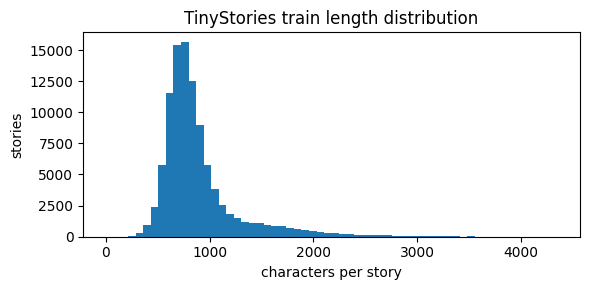

story length: mean 897, median 788, max 4349


In [5]:
# Fixed-length input -> target windows (shown for one example)
T = CFG["model"]["block_size"]
x_demo, y_demo = train_ids[:T], train_ids[1:T + 1]
print("input  :", repr(decode(x_demo[:70])))
print("target :", repr(decode(y_demo[:70])), "   <- same text shifted left by one character")
print("windows per epoch:", (len(train_ids) - 1) // T)

lengths = [len(s) for s in train_txt]
plt.figure(figsize=(6, 3))
plt.hist(lengths, bins=60)
plt.xlabel("characters per story"); plt.ylabel("stories"); plt.title("TinyStories train length distribution")
plt.tight_layout(); plt.savefig(DIRS["outputs"] / "story_length_hist.png", dpi=120); plt.show()
log(f"story length: mean {np.mean(lengths):.0f}, median {np.median(lengths):.0f}, max {max(lengths)}")

train_data = torch.from_numpy(train_ids.copy()).to(device)   # uint8 on GPU: ~1 byte / char
val_data = torch.from_numpy(val_ids.copy()).to(device)
train_words = E.training_word_vocab(train_txt)

## 1.2 GPT model — written from scratch
One `Block` = pre-norm **multi-head causal self-attention** + pre-norm **feed-forward network**,
each wrapped in a **residual connection**. Pre-norm (LayerNorm *before* each sub-layer, as in GPT-2)
is used instead of the post-norm of Vaswani et al. (2017) because it trains more stably without
careful warm-up tuning. The causal mask sets attention scores for future positions to −∞ before the softmax.

In [6]:
class LayerNorm(nn.Module):
    """y = (x - mean) / sqrt(var + eps) * gamma + beta, over the last dimension."""
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d))
        self.bias = nn.Parameter(torch.zeros(d))
        self.eps = eps

    def forward(self, x):
        xf = x.float()                              # compute statistics in fp32 even under AMP
        mu = xf.mean(-1, keepdim=True)
        var = xf.var(-1, keepdim=True, unbiased=False)
        y = (xf - mu) / torch.sqrt(var + self.eps)
        return (y * self.weight + self.bias).to(x.dtype)


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, block_size, dropout):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.d_head = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model)      # Q, K, V projections for all heads at once
        self.proj = nn.Linear(d_model, d_model)         # output projection W_O
        self.attn_drop, self.resid_drop = nn.Dropout(dropout), nn.Dropout(dropout)
        mask = torch.tril(torch.ones(block_size, block_size, dtype=torch.bool))
        self.register_buffer("causal_mask", mask.view(1, 1, block_size, block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, heads, T, d_head)
        q = q.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)          # (B, h, T, T)
        scores = scores.masked_fill(~self.causal_mask[:, :, :T, :T], float("-inf"))
        att = F.softmax(scores.float(), dim=-1).to(q.dtype)                  # row i attends to j <= i only
        att = self.attn_drop(att)
        y = (att @ v).transpose(1, 2).contiguous().view(B, T, C)             # concatenate heads
        return self.resid_drop(self.proj(y))


class FeedForward(nn.Module):
    def __init__(self, d_model, mult, dropout):
        super().__init__()
        self.fc1 = nn.Linear(d_model, mult * d_model)
        self.fc2 = nn.Linear(mult * d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.fc2(F.gelu(self.fc1(x))))


class Block(nn.Module):
    def __init__(self, d_model, n_head, block_size, dropout, mult):
        super().__init__()
        self.ln1, self.ln2 = LayerNorm(d_model), LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_head, block_size, dropout)
        self.ffn = FeedForward(d_model, mult, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))     # residual connection 1
        x = x + self.ffn(self.ln2(x))      # residual connection 2
        return x


class GPT(nn.Module):
    def __init__(self, vocab_size, n_layer, n_head, d_model, block_size, dropout, ffn_mult=4, tie_weights=True):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)       # learnable token embeddings
        self.pos_emb = nn.Embedding(block_size, d_model)       # learnable positional embeddings
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(d_model, n_head, block_size, dropout, ffn_mult) for _ in range(n_layer)])
        self.ln_f = LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)   # language-modelling head
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight
        self.apply(self._init)
        for name, p in self.named_parameters():                    # GPT-2 scaled init of residual outputs
            if name.endswith("proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx):
        B, T = idx.shape
        assert T <= self.block_size, "sequence longer than block_size"
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos)[None, :, :])
        for blk in self.blocks:
            x = blk(x)
        return self.lm_head(self.ln_f(x))       # (B, T, vocab) logits

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        """temperature <= 0 -> greedy decoding; otherwise temperature sampling."""
        self.eval()
        for _ in range(max_new_tokens):
            logits = self(idx[:, -self.block_size:])[:, -1, :].float()
            if temperature <= 0:
                nxt = logits.argmax(-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k:
                    v, _ = torch.topk(logits, top_k)
                    logits[logits < v[:, [-1]]] = -float("inf")
                nxt = torch.multinomial(F.softmax(logits, dim=-1), 1)
            idx = torch.cat([idx, nxt], dim=1)
        return idx


MC = CFG["model"]
model = GPT(VOCAB, MC["n_layer"], MC["n_head"], MC["d_model"], MC["block_size"], MC["dropout"],
            MC.get("ffn_mult", 4), MC.get("tie_weights", True)).to(device)
N_PARAMS = sum(p.numel() for p in model.parameters())
N_PARAMS_NON_EMB = N_PARAMS - model.pos_emb.weight.numel() - (0 if MC.get("tie_weights", True) else model.tok_emb.weight.numel())
log(f"parameters: {N_PARAMS:,} total ({N_PARAMS_NON_EMB:,} excluding embeddings)")
print(model)

parameters: 3,249,152 total (3,183,616 excluding embeddings)
GPT(
  (tok_emb): Embedding(94, 256)
  (pos_emb): Embedding(256, 256)
  (drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (ln1): LayerNorm()
      (ln2): LayerNorm()
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=256, out_features=768, bias=True)
        (proj): Linear(in_features=256, out_features=256, bias=True)
        (attn_drop): Dropout(p=0.1, inplace=False)
        (resid_drop): Dropout(p=0.1, inplace=False)
      )
      (ffn): FeedForward(
        (fc1): Linear(in_features=256, out_features=1024, bias=True)
        (fc2): Linear(in_features=1024, out_features=256, bias=True)
        (drop): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm()
  (lm_head): Linear(in_features=256, out_features=94, bias=False)
)


In [7]:
# Unit test: the causal mask really hides the future.
# Changing the LAST token must not change the logits at any EARLIER position.
model.eval()
with torch.no_grad():
    a = torch.randint(0, VOCAB, (1, 32), device=device)
    b = a.clone(); b[0, -1] = (b[0, -1] + 1) % VOCAB
    la, lb = model(a), model(b)
    earlier_same = torch.allclose(la[0, :-1], lb[0, :-1], atol=1e-5)
    last_differs = not torch.allclose(la[0, -1], lb[0, -1], atol=1e-5)
log(f"causal-mask test: earlier positions unchanged = {earlier_same}, last position changed = {last_differs}")
assert earlier_same, "causal mask is leaking future tokens!"

causal-mask test: earlier positions unchanged = True, last position changed = True


## 1.3 Training
* **Loss** — next-character cross-entropy.
* **Optimiser** — AdamW. Weight decay applies only to weight matrices (not biases, LayerNorm, or embeddings).
* **LR schedule** — linear warm-up for `warmup_steps`, then cosine or linear decay to `min_lr` (set in config).
  Warm-up keeps Adam from taking huge steps while its variance estimates are still noisy.
* **Epoch** — one full pass over all non-overlapping `block_size` windows of the 100K-story training
  stream. A random offset each epoch means the model sees different window boundaries.
* **Stability tracking** — gradient norm every step (before clipping), loss spikes
  (loss > `spike_factor` × EMA of recent loss), NaN/Inf losses, and AMP overflow skips.
* A checkpoint is saved every epoch, so a Colab disconnect can resume instead of restarting.

In [8]:
TC = CFG["train"]
B, EPOCHS = TC["batch_size"], TC["epochs"]
n_windows = (len(train_data) - 1 - T) // T
STEPS_PER_EPOCH = n_windows // B
TOTAL_STEPS = EPOCHS * STEPS_PER_EPOCH
USE_AMP = bool(TC.get("amp", True)) and device.type == "cuda"

def lr_at(step):
    if step < TC["warmup_steps"]:
        return TC["lr"] * (step + 1) / TC["warmup_steps"]
    frac = (step - TC["warmup_steps"]) / max(1, TOTAL_STEPS - TC["warmup_steps"])
    frac = min(max(frac, 0.0), 1.0)
    if TC.get("schedule", "cosine") == "cosine":
        return TC["min_lr"] + 0.5 * (TC["lr"] - TC["min_lr"]) * (1 + math.cos(math.pi * frac))
    return TC["lr"] - (TC["lr"] - TC["min_lr"]) * frac          # linear decay

decay = [p for n, p in model.named_parameters() if p.dim() >= 2 and "emb" not in n]
no_decay = [p for n, p in model.named_parameters() if not (p.dim() >= 2 and "emb" not in n)]
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": TC["weight_decay"]},
                               {"params": no_decay, "weight_decay": 0.0}],
                              lr=TC["lr"], betas=tuple(TC["betas"]))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

CKPT_BEST, CKPT_LAST = DIRS["checkpoints"] / "best.pt", DIRS["checkpoints"] / "last.pt"
state = {"epoch": 0, "step": 0, "best_val": float("inf"), "history": [], "step_log": [],
         "nan_count": 0, "spike_count": 0, "amp_skips": 0, "train_seconds": 0.0, "train_tokens": 0}
if TC.get("resume", True) and CKPT_LAST.exists():
    ck = torch.load(CKPT_LAST, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scaler.load_state_dict(ck["scaler"])
    state = ck["state"]; torch.set_rng_state(ck["rng_cpu"])
    log(f"RESUMED from {CKPT_LAST.name} at epoch {state['epoch']}")
log(f"steps/epoch = {STEPS_PER_EPOCH:,} | total steps = {TOTAL_STEPS:,} | tokens/step = {B * T:,} | AMP = {USE_AMP}")

steps/epoch = 2,739 | total steps = 27,390 | tokens/step = 32,768 | AMP = True


In [9]:
def save_ckpt(path, include_optimizer):
    obj = {"model": model.state_dict(), "config": CFG, "vocab": idx_to_char, "state": state}
    if include_optimizer:
        obj.update(optimizer=optimizer.state_dict(), scaler=scaler.state_dict(), rng_cpu=torch.get_rng_state())
    torch.save(obj, path)

offsets = torch.arange(T, device=device)
reset_peak_memory(device)
ema = None
try:
    for epoch in range(state["epoch"], EPOCHS):
        model.train()
        g = torch.Generator(device="cpu").manual_seed(SEED + epoch)
        start_off = int(torch.randint(0, T, (1,), generator=g))
        starts = (torch.randperm(n_windows, generator=g)[: STEPS_PER_EPOCH * B] * T + start_off).to(device)
        ep_loss, ep_gn, t0 = 0.0, [], time.perf_counter()
        for i in range(STEPS_PER_EPOCH):
            step = state["step"]
            for grp in optimizer.param_groups:
                grp["lr"] = lr_at(step)
            idx = starts[i * B:(i + 1) * B, None] + offsets[None, :]
            x, y = train_data[idx].long(), train_data[idx + 1].long()
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = F.cross_entropy(logits.float().view(-1, VOCAB), y.view(-1))
            if not torch.isfinite(loss):
                state["nan_count"] += 1
                log(f"  non-finite loss at step {step}; skipping update")
                optimizer.zero_grad(set_to_none=True); state["step"] += 1
                continue
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), TC["grad_clip"]).item()
            scale_before = scaler.get_scale()
            scaler.step(optimizer); scaler.update()
            if USE_AMP and scaler.get_scale() < scale_before:
                state["amp_skips"] += 1
            lv = loss.item()
            if ema is not None and step > TC["warmup_steps"] and lv > TC["spike_factor"] * ema:
                state["spike_count"] += 1
                log(f"  loss spike at step {step}: {lv:.3f} vs EMA {ema:.3f}")
            ema = lv if ema is None else 0.98 * ema + 0.02 * lv
            ep_loss += lv; ep_gn.append(gnorm if math.isfinite(gnorm) else float("nan"))
            state["step"] += 1
            if step % 50 == 0:
                state["step_log"].append({"step": step, "epoch": epoch, "loss": lv, "grad_norm": gnorm, "lr": lr_at(step)})
            if step % max(1, STEPS_PER_EPOCH // 5) == 0:
                log(f"  ep {epoch + 1} step {step:>7}/{TOTAL_STEPS} loss {lv:.4f} gnorm {gnorm:.3f} lr {lr_at(step):.2e}")
        if device.type == "cuda":
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        state["train_seconds"] += dt
        state["train_tokens"] += STEPS_PER_EPOCH * B * T
        tr_eval = E.evaluate_lm(model, train_data, T, B, TC["eval_max_seqs"], device, USE_AMP)
        va_eval = E.evaluate_lm(model, val_data, T, B, TC["eval_max_seqs"], device, USE_AMP)
        rec = {"epoch": epoch + 1, "train_loss_running": ep_loss / STEPS_PER_EPOCH, "train_loss": tr_eval["loss"],
               "val_loss": va_eval["loss"], "val_acc": va_eval["acc"], "val_ppl": va_eval["ppl"],
               "grad_norm_mean": float(np.nanmean(ep_gn)), "grad_norm_max": float(np.nanmax(ep_gn)),
               "lr_end": lr_at(state["step"]), "epoch_seconds": dt}
        state["history"].append(rec); state["epoch"] = epoch + 1
        log(f"EPOCH {epoch + 1}/{EPOCHS}: train {tr_eval['loss']:.4f} | val {va_eval['loss']:.4f} "
            f"(ppl {va_eval['ppl']:.3f}, acc {va_eval['acc']:.3f}) | gnorm mean {rec['grad_norm_mean']:.3f} | {dt / 60:.1f} min")
        if va_eval["loss"] < state["best_val"]:
            state["best_val"] = va_eval["loss"]; state["best_epoch"] = epoch + 1
            save_ckpt(CKPT_BEST, include_optimizer=False)
            log(f"  new best val loss -> saved {CKPT_BEST.name}")
        save_ckpt(CKPT_LAST, include_optimizer=True)
except Exception as err:
    log.exception(err)
    raise
PEAK_TRAIN_MB = peak_memory_mb(device)
log(f"training done: {state['train_seconds'] / 60:.1f} min, peak memory {PEAK_TRAIN_MB:.0f} MB")

  ep 1 step       0/27390 loss 4.5425 gnorm 8.938 lr 2.00e-06
  ep 1 step     547/27390 loss 1.3752 gnorm 0.795 lr 1.00e-03
  ep 1 step    1094/27390 loss 1.0007 gnorm 0.423 lr 9.99e-04
  ep 1 step    1641/27390 loss 0.8773 gnorm 0.316 lr 9.96e-04
  ep 1 step    2188/27390 loss 0.8243 gnorm 0.305 lr 9.91e-04
  ep 1 step    2735/27390 loss 0.8244 gnorm 0.262 lr 9.85e-04
EPOCH 1/10: train 0.7554 | val 0.7602 (ppl 2.139, acc 0.760) | gnorm mean 0.535 | 1.1 min
  new best val loss -> saved best.pt
  ep 2 step    3282/27390 loss 0.7838 gnorm 0.243 lr 9.76e-04
  ep 2 step    3829/27390 loss 0.7652 gnorm 0.215 lr 9.66e-04
  ep 2 step    4376/27390 loss 0.7660 gnorm 0.211 lr 9.55e-04
  ep 2 step    4923/27390 loss 0.7699 gnorm 0.202 lr 9.41e-04
  ep 2 step    5470/27390 loss 0.7383 gnorm 0.192 lr 9.26e-04
EPOCH 2/10: train 0.6984 | val 0.7046 (ppl 2.023, acc 0.777) | gnorm mean 0.217 | 1.1 min
  new best val loss -> saved best.pt
  ep 3 step    6017/27390 loss 0.7434 gnorm 0.205 lr 9.10e-04
  

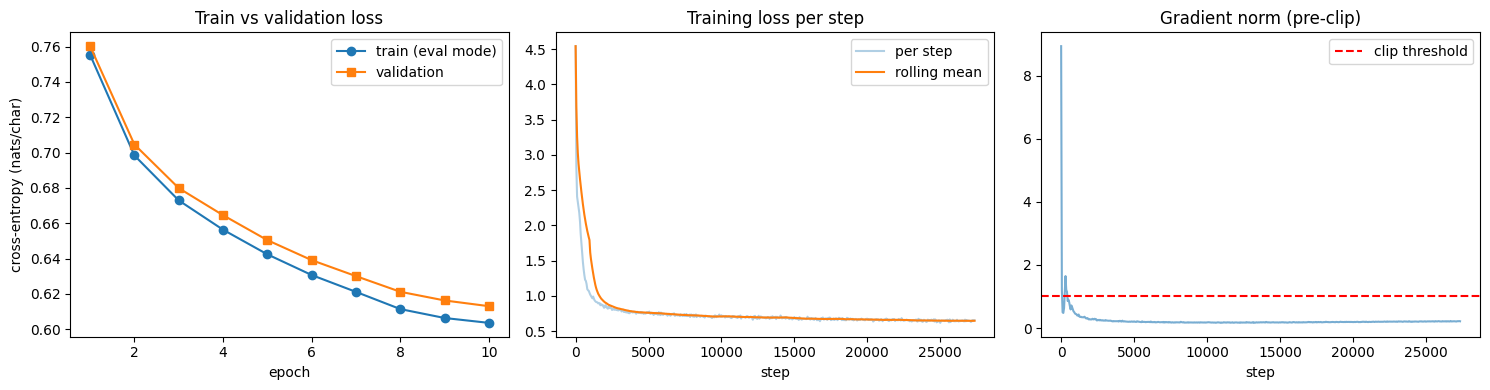

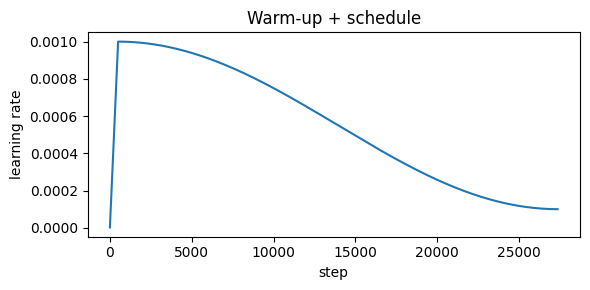

In [10]:
hist = pd.DataFrame(state["history"]); steps = pd.DataFrame(state["step_log"])
hist.to_csv(DIRS["outputs"] / "epoch_history.csv", index=False)
steps.to_csv(DIRS["outputs"] / "step_log.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(hist["epoch"], hist["train_loss"], "o-", label="train (eval mode)")
ax[0].plot(hist["epoch"], hist["val_loss"], "s-", label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy (nats/char)"); ax[0].set_title("Train vs validation loss"); ax[0].legend()
ax[1].plot(steps["step"], steps["loss"], alpha=0.35, label="per step")
ax[1].plot(steps["step"], steps["loss"].rolling(20, min_periods=1).mean(), label="rolling mean")
ax[1].set_xlabel("step"); ax[1].set_title("Training loss per step"); ax[1].legend()
ax[2].plot(steps["step"], steps["grad_norm"], alpha=0.6)
ax[2].axhline(TC["grad_clip"], ls="--", c="r", label="clip threshold")
ax[2].set_xlabel("step"); ax[2].set_title("Gradient norm (pre-clip)"); ax[2].legend()
plt.tight_layout(); plt.savefig(DIRS["outputs"] / "loss_curves.png", dpi=130); plt.show()

plt.figure(figsize=(6, 3)); plt.plot(steps["step"], steps["lr"]); plt.xlabel("step"); plt.ylabel("learning rate")
plt.title("Warm-up + schedule"); plt.tight_layout(); plt.savefig(DIRS["outputs"] / "lr_schedule.png", dpi=120); plt.show()

## Evaluation with the best checkpoint
The final numbers use the **full** validation set. "Train loss" is measured in eval mode on the
same number of windows, so the generalisation gap is a like-for-like comparison.

In [11]:
best = torch.load(CKPT_BEST, map_location=device, weights_only=False)
model.load_state_dict(best["model"])
n_val_seqs = (len(val_data) - 1) // T
final_val = E.evaluate_lm(model, val_data, T, B, None, device, USE_AMP)
final_train = E.evaluate_lm(model, train_data, T, B, n_val_seqs, device, USE_AMP)
log(f"FINAL (best epoch {state.get('best_epoch')}): train {final_train['loss']:.4f} | val {final_val['loss']:.4f} | "
    f"ppl {final_val['ppl']:.3f} | bpc {final_val['bpc']:.3f} | acc {final_val['acc']:.4f}")

FINAL (best epoch 10): train 0.6077 | val 0.6150 | ppl 1.850 | bpc 0.887 | acc 0.8042


## Text generation
Greedy decoding (temperature 0) plus temperature sampling. Samples are cut at the first
end-of-story token. Diversity metrics are computed per decoding setting.

In [12]:
GC = CFG["generation"]
set_seed(SEED)

def gen(prompt, temperature, n_new):
    ids = torch.tensor(encode(prompt), dtype=torch.long, device=device)[None, :]
    out = model.generate(ids, n_new, temperature=temperature, top_k=GC.get("top_k"))
    text = decode(out[0].tolist())
    return text.split(EOS)[0] if EOS in text[len(prompt):] else text

# generation speed: batch of 1, fixed length, after one warm-up call
_ = gen(GC["prompts"][0], 1.0, 20)
with Timer() as tg:
    _ = model.generate(torch.tensor(encode(GC["prompts"][0]), dtype=torch.long, device=device)[None, :],
                       GC["max_new_chars"], temperature=1.0)
GEN_TOK_PER_SEC = GC["max_new_chars"] / tg.seconds

samples = []
for prompt in GC["prompts"]:
    for temp in GC["temperatures"]:
        reps = 1 if temp <= 0 else GC["samples_per_prompt"]
        for r in range(reps):
            txt = gen(prompt, temp, GC["max_new_chars"])
            samples.append({"prompt": prompt, "temperature": temp, "rep": r, "text": txt,
                            "repeat4": E.repeated_ngram_rate(txt), "nonword": E.nonword_rate(txt, train_words)})

gen_rows = []
for temp in GC["temperatures"]:
    ss = [s["text"] for s in samples if s["temperature"] == temp]
    gm = E.generation_metrics(ss, train_words)
    gen_rows.append({"temperature": temp, "n_samples": len(ss), **gm})
gen_df = pd.DataFrame(gen_rows)
display_df = gen_df.round(4)
print(display_df.to_string(index=False))

with open(DIRS["outputs"] / "samples.txt", "w", encoding="utf-8") as f:
    for s in samples:
        f.write(f"### prompt={s['prompt']!r} temperature={s['temperature']} rep={s['rep']} "
                f"repeat4={s['repeat4']:.3f} nonword={s['nonword']:.3f}\n{s['text']}\n\n")
(DIRS["outputs"] / "samples.json").write_text(json.dumps(samples, indent=1, ensure_ascii=False))
gen_df.to_csv(DIRS["outputs"] / "generation_metrics.csv", index=False)
for s in samples[:4]:
    print(f"\n--- T={s['temperature']} ---\n{s['text']}")

 temperature  n_samples  distinct_1  distinct_2  distinct_3  repeated_4gram_rate  nonword_rate
         0.0          5      0.2542      0.4660      0.5577               0.3429        0.0000
         0.7         10      0.2978      0.7123      0.8766               0.0185        0.0036
         1.0         10      0.3392      0.7763      0.9295               0.0045        0.0081

--- T=0.0 ---
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine and explore the world around her. One day, she found a big box in the garden. It was a big box with a big box of colorful colorful colors. 

Lily was so happy to see the box and she put it in her pocket. She put it in her pocket and started to play with it. She put it in her pocket and started to play with it. She was 

--- T=0.7 ---
Once upon a time, there was a popular creature named Rose. Rose lived in a big forest with lots of trees. One day, Rose was walking with her friends when she saw something a

## All Task 1 metrics → `metrics_report.csv`
The headline generation metrics use the temperature in `generation.headline_temperature`.

In [13]:
head = gen_df.set_index("temperature").loc[GC["headline_temperature"]]
H = pd.DataFrame(state["history"])
ckpt_id = file_sha(CKPT_BEST)
metrics = [
    ("train_cross_entropy", final_train["loss"], "nats/char, eval mode, best checkpoint"),
    ("val_cross_entropy", final_val["loss"], "nats/char, full validation set"),
    ("perplexity", final_val["ppl"], "exp(val CE), character level"),
    ("bits_per_character", final_val["bpc"], "val CE / ln 2"),
    ("generalization_gap", final_val["loss"] - final_train["loss"], "val CE - train CE"),
    ("top1_next_char_accuracy", final_val["acc"], "validation"),
    ("distinct_1", head["distinct_1"], f"word level, T={GC['headline_temperature']}"),
    ("distinct_2", head["distinct_2"], f"word level, T={GC['headline_temperature']}"),
    ("distinct_3", head["distinct_3"], f"word level, T={GC['headline_temperature']}"),
    ("repeated_4gram_rate", head["repeated_4gram_rate"], f"word level, T={GC['headline_temperature']}"),
    ("greedy_repeated_4gram_rate", gen_df.set_index("temperature").loc[0.0]["repeated_4gram_rate"]
     if 0.0 in GC["temperatures"] else float("nan"), "greedy decoding"),
    ("grad_norm_mean", float(H["grad_norm_mean"].mean()), "pre-clip, all epochs"),
    ("grad_norm_max", float(H["grad_norm_max"].max()), "pre-clip, all epochs"),
    ("loss_spikes", state["spike_count"], f"loss > {TC['spike_factor']} x EMA after warm-up"),
    ("nan_losses", state["nan_count"], "non-finite training losses"),
    ("amp_overflow_skips", state["amp_skips"], "fp16 steps skipped by GradScaler"),
    ("parameter_count", N_PARAMS, "unique trainable parameters"),
    ("train_tokens_per_sec", state["train_tokens"] / max(state["train_seconds"], 1e-9), "excludes eval time"),
    ("generation_tokens_per_sec", GEN_TOK_PER_SEC, f"batch 1, {GC['max_new_chars']} chars"),
    ("peak_memory_mb", PEAK_TRAIN_MB, "torch.cuda.max_memory_allocated during training"),
    ("total_training_time_min", state["train_seconds"] / 60, "sum of epoch times"),
    ("epochs", state["epoch"], ""),
    ("best_epoch", state.get("best_epoch"), ""),
    ("checkpoint_id", ckpt_id, "sha256[:12] of checkpoints/best.pt"),
    ("hardware", HW.get("gpu", "cpu") + " / " + HW["cpu"], ""),
]
mdf = pd.DataFrame(metrics, columns=["metric", "value", "notes"])
mdf.to_csv(OUT_ROOT / "metrics_report.csv", index=False)
print(mdf.to_string(index=False))

                    metric                                                    value                                           notes
       train_cross_entropy                                                 0.607741           nats/char, eval mode, best checkpoint
         val_cross_entropy                                                 0.615038                  nats/char, full validation set
                perplexity                                                 1.849727                    exp(val CE), character level
        bits_per_character                                                 0.887312                                   val CE / ln 2
        generalization_gap                                                 0.007297                               val CE - train CE
   top1_next_char_accuracy                                                  0.80421                                      validation
                distinct_1                                                 0

## 1.4 Failure analysis — draft
The notebook ranks samples with two automatic signals: repeated 4-gram rate (repetition) and
non-word rate (invented or broken words). It pre-fills `failure_analysis.md` with three candidate
snippets. **Read every sample in `outputs/samples.txt` yourself.** Replace a candidate if you find a
clearer failure (e.g. loss of coherence, where a character's name changes or the plot contradicts
itself), and write each observation in your own words. You will be asked about these in the viva.

In [14]:
by_rep = sorted(samples, key=lambda s: -s["repeat4"])
by_nonword = sorted([s for s in samples if s["temperature"] > 0], key=lambda s: -s["nonword"])
hot = [s for s in samples if s["temperature"] == max(GC["temperatures"])]
picked, seen = [], set()
for cand, kind in [(by_rep, "Repetition / looping"), (by_nonword, "Broken spelling / invented words"),
                   (hot, "Loss of coherence (check manually)")]:
    for s in cand:
        if id(s) not in seen:
            picked.append((kind, s)); seen.add(id(s)); break

lines = [f"# Task 1 — Failure analysis ({MEMBER})", "",
         f"Checkpoint `{ckpt_id}` (best epoch {state.get('best_epoch')}). All snippets come from `outputs/samples.txt`.", ""]
for i, (kind, s) in enumerate(picked, 1):
    lines += [f"## Failure {i}: {kind}", "",
              f"*Prompt:* `{s['prompt']}` · *temperature:* {s['temperature']} · repeated-4-gram rate {s['repeat4']:.2f} · non-word rate {s['nonword']:.2f}",
              "", "```text", s["text"][:600], "```", "",
              "**Failure type:** " + kind, "",
              "**Observation (write in your own words):** TODO — what exactly goes wrong, where it starts, "
              "and *why* a character-level model with this context length / size / decoding setting produces it.", ""]
lines += ["## Summary", "", "TODO — one paragraph linking the three failures to model size, context length, "
          "decoding temperature, and character-level tokenisation."]
fa_path = OUT_ROOT / "failure_analysis.md"
if not fa_path.exists() or is_smoke():        # never overwrite a write-up you've already edited
    fa_path.write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines[:40]))

# Task 1 — Failure analysis (ruchika_chaurasia)

Checkpoint `bceaa3cfc2f2` (best epoch 10). All snippets come from `outputs/samples.txt`.

## Failure 1: Repetition / looping

*Prompt:* `The big red ball` · *temperature:* 0.0 · repeated-4-gram rate 0.46 · non-word rate 0.00

```text
The big red ball was so happy to have a new friend. They played together all day long. The big red ball was so happy to have a new friend. They played together all day long. The end.
```

**Failure type:** Repetition / looping

**Observation (write in your own words):** TODO — what exactly goes wrong, where it starts, and *why* a character-level model with this context length / size / decoding setting produces it.

## Failure 2: Broken spelling / invented words

*Prompt:* `Once upon a time` · *temperature:* 1.0 · repeated-4-gram rate 0.00 · non-word rate 0.05

```text
Once upon a time there was a boy called Janna. One day Janna wanted to go for a walk in the forest all day. She walked to the forest and final

## results.md + reproducibility manifest

In [15]:
def md_table(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(f"{v:.4g}" if isinstance(v, float) else str(v) for v in r.values) + " |")
    return "\n".join(out)

arch = (f"{MC['n_layer']} pre-norm Transformer blocks, {MC['n_head']} heads, d_model {MC['d_model']}, "
        f"FFN {MC.get('ffn_mult', 4)}x GELU, context {MC['block_size']} chars, dropout {MC['dropout']}, "
        f"tied embeddings={MC.get('tie_weights', True)}, vocab {VOCAB}")
hp = (f"AdamW lr {TC['lr']} -> {TC['min_lr']} ({TC['schedule']}), warm-up {TC['warmup_steps']} steps, "
      f"batch {B}x{T} chars, wd {TC['weight_decay']}, betas {tuple(TC['betas'])}, clip {TC['grad_clip']}, "
      f"epochs {EPOCHS}, AMP {USE_AMP}, seed {SEED}")
results = f"""# Task 1 — GPT from scratch · {MEMBER} (lineup {CFG.get('lineup')})

## What I built
{arch}.

**Hyper-parameters:** {hp}.

## Why (design justification)
{CFG.get('rationale', 'TODO')}

## Metrics (best checkpoint `{ckpt_id}`, epoch {state.get('best_epoch')})
{md_table(mdf)}

### Generation metrics per decoding temperature
{md_table(gen_df)}

## Evidence
* Loss curves: `outputs/loss_curves.png`, LR schedule: `outputs/lr_schedule.png`
* Per-epoch history: `outputs/epoch_history.csv`; per-step log: `outputs/step_log.csv`
* Samples: `outputs/samples.txt` / `outputs/samples.json`
* Raw log: `{log.path.relative_to(REPO_ROOT)}`
* Checkpoint: `checkpoints/best.pt` (ID `{ckpt_id}`)
* Failure analysis: `failure_analysis.md`

## Hardware
{json.dumps(HW)}
"""
(OUT_ROOT / "results.md").write_text(results, encoding="utf-8")
man = write_manifest(REPO_ROOT, TASK, MEMBER, CFG, {"best": CKPT_BEST},
                     [OUT_ROOT / "metrics_report.csv", OUT_ROOT / "results.md", DIRS["outputs"] / "loss_curves.png"],
                     extra={"raw_log": str(log.path.relative_to(REPO_ROOT))})
log("wrote results.md, metrics_report.csv, manifest:", man.relative_to(REPO_ROOT))
log.close()

wrote results.md, metrics_report.csv, manifest: reproducibility/manifests/task1_llm_ruchika_chaurasia_20261002_000259.json
